# Интеграл и накопление ошибок округления

**Задача.** Найти $I_k=\int_0^1 x^k e^x\,dx$ для $k=1,\ldots,20$ и объяснить, почему прямая рекурсия сначала даёт правильный график, а затем расходится с точным решением.

Для повторного запуска: Python 3, NumPy и Matplotlib. Все значения и графики вычисляются из формул.

### 1. Прямая рекурсия

База: $I_0=\int_0^1 e^x\,dx=e-1$. Для $k\ge1$ берём $u=x^k$, $dv=e^x\,dx$. Интегрирование по частям даёт

$$
I_k=[x^k e^x]_0^1 - k\int_0^1 x^{k-1}e^x\,dx=e-kI_{k-1}.
$$

Из определения видно, что $I_k>0$ и $I_{k+1}<I_k$: при $0<x<1$ увеличение степени уменьшает $x^k$. Кроме того, $1/(k+1)\le I_k\le e/(k+1)$, поэтому $I_k\to0$. Рост и отрицательные значения на графике сразу выдают вычислительную ошибку.

In [1]:
from decimal import Decimal, localcontext
import math
import numpy as np
import matplotlib.pyplot as plt

K = 20
ks = np.arange(1, K + 1)

def forward(k_max, dtype=np.float64, e_value=math.e):
    # И e, и промежуточные операции имеют выбранную точность.
    e = dtype(e_value)
    values = np.empty(k_max + 1, dtype=dtype)
    values[0] = e - dtype(1)
    for k in range(1, k_max + 1):
        values[k] = e - dtype(k) * values[k - 1]
    return values

direct64 = forward(K)
direct32 = forward(K, np.float32)

### 2. Два способа проверить результат

**Ряд.** Подставим равномерно сходящийся на $[0,1]$ ряд $e^x=\sum_{j=0}^{\infty} x^j/j!$. После почленного интегрирования получаем
$$
I_k=\sum_{j=0}^{\infty}\frac{1}{j!(k+j+1)}.
$$
Все слагаемые положительны. Берём 50 слагаемых с десятичной точностью 60 знаков. Отношение соседних членов хвоста начиная с $j=50$ не превосходит $1/51$, поэтому отброшенный хвост не больше $\frac{51}{50}\frac{1}{50!(k+51)}<10^{-65}$. Для $k=1$ берём точное значение $I_1=e-(e-1)=1$, чтобы на графике ошибки не принять остаток округления самого ряда за ошибку рекурсии.

**Обратная рекурсия.** Переставим члены: $I_{k-1}=(e-I_k)/k$. Возьмём $I_{40}\approx0$ и спустимся до $I_0$. Стартовая ошибка делится на 40, затем на 39 и так далее. В точной арифметике её вклад в $I_k$ не больше $\frac{e}{41}\frac{k!}{40!}$. Для $k\le20$ это меньше $2\cdot10^{-31}$; на практике остаются ошибки округления порядка машинной точности.

In [2]:
def reference_series(k, terms=50):
    with localcontext() as ctx:
        ctx.prec = 60
        return sum(
            (Decimal(1) / (math.factorial(j) * (k + j + 1))
             for j in range(terms)),
            Decimal(0),
        )

def backward(k_max, start=40):
    if start <= k_max:
        raise ValueError("Начальный индекс должен быть больше k_max")
    values = np.zeros(start + 1)
    for k in range(start, 0, -1):
        values[k - 1] = (math.e - values[k]) / k
    return values[:k_max + 1]

reference = [reference_series(k) for k in range(K + 1)]
assert abs(reference[1] - 1) < Decimal("1e-58")
reference[1] = Decimal(1)
reference_plot = np.array([float(value) for value in reference])
reverse = backward(K)

def absolute_errors(values):
    # Сравнение с Decimal видит ошибки меньше одного шага float64.
    with localcontext() as ctx:
        ctx.prec = 60
        return np.array([
            float(abs(Decimal.from_float(float(value)) - ref))
            for value, ref in zip(values, reference)
        ])

err32 = absolute_errors(direct32)
err64 = absolute_errors(direct64)
err_reverse = absolute_errors(reverse)

print(f"{'k':>2}  {'Прямая float64':>16}  {'Обратная':>14}  {'Ряд':>14}  {'|Ошибка float64|':>17}")
for k in ks:
    print(f"{k:2d}  {direct64[k]:16.9f}  {reverse[k]:14.9f}  "
          f"{reference[k]:14.9f}  {err64[k]:17.3e}")
print(f"\nМаксимальная абсолютная ошибка обратного расчёта (k=1…20): {max(err_reverse[1:]):.2e}")

assert np.all(np.diff(reference_plot) < 0)
assert np.all((1.0 / (ks + 1) < reference_plot[1:])
              & (reference_plot[1:] < math.e / (ks + 1)))
assert max(err_reverse[1:]) < 1e-15

 k    Прямая float64        Обратная             Ряд   |Ошибка float64|
 1       1.000000000     1.000000000     1.000000000          0.000e+00
 2       0.718281828     0.718281828     0.718281828          1.446e-16
 3       0.563436343     0.563436343     0.563436343          2.891e-16
 4       0.464536456     0.464536456     0.464536456          1.301e-15
 5       0.395599548     0.395599548     0.395599548          6.361e-15
 6       0.344684542     0.344684542     0.344684542          3.831e-14
 7       0.305490037     0.305490037     0.305490037          2.680e-13
 8       0.274361533     0.274361533     0.274361533          2.144e-12
 9       0.249028031     0.249028031     0.249028031          1.930e-11
10       0.228001515     0.228001515     0.228001515          1.930e-10
11       0.210265160     0.210265158     0.210265158          2.123e-09
12       0.195099906     0.195099931     0.195099931          2.547e-08
13       0.181983055     0.181982723     0.181982723          3.

### 3. Где портится график

Слева — первые 14 шагов, справа — весь диапазон задачи. На нижнем графике логарифмическая шкала показывает, на сколько порядков выросла ошибка. Точки с нулевой вычисленной ошибкой на логарифмической шкале пропущены.

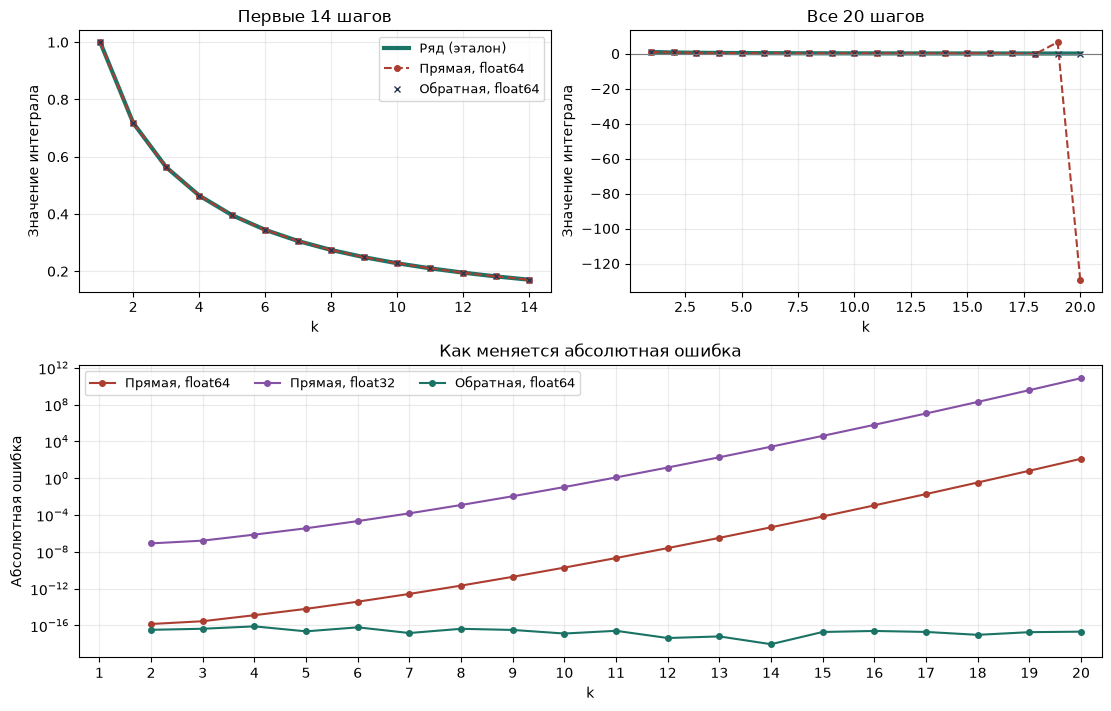

In [3]:
%matplotlib inline
fig = plt.figure(figsize=(11, 7), layout="constrained")
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.12])
early = fig.add_subplot(grid[0, 0])
full = fig.add_subplot(grid[0, 1])
error_ax = fig.add_subplot(grid[1, :])

for ax, stop, title in [(early, 14, "Первые 14 шагов"),
                        (full, K, "Все 20 шагов")]:
    s = slice(1, stop + 1)
    ax.plot(ks[:stop], reference_plot[s], color="#1a7365", lw=3,
            label="Ряд (эталон)")
    ax.plot(ks[:stop], direct64[s], "o--", color="#ac3d31", ms=4,
            label="Прямая, float64")
    ax.plot(ks[:stop], reverse[s], "x", color="#273752", ms=5,
            label="Обратная, float64")
    ax.set(title=title, xlabel="k", ylabel="Значение интеграла")
    ax.grid(alpha=0.25)

early.legend(fontsize=9)
full.axhline(0, color="#7a7a7a", lw=0.8)

for errors, label, color in [
    (err64, "Прямая, float64", "#ac3d31"),
    (err32, "Прямая, float32", "#8451a4"),
    (err_reverse, "Обратная, float64", "#1a7365"),
]:
    plotted = np.where(errors[1:] > 0, errors[1:], np.nan)
    error_ax.semilogy(ks, plotted, "o-", color=color, ms=4, label=label)
error_ax.set(title="Как меняется абсолютная ошибка", xlabel="k",
             ylabel="Абсолютная ошибка", xticks=ks, xlim=(0.6, 20.4))
error_ax.grid(alpha=0.25)
error_ax.legend(ncol=3, fontsize=9, loc="upper left")

plt.show()

### 4. Почему у всех может быть разный график

Пусть $\widehat I_k$ — вычисленное значение, а $\delta_k=\widehat I_k-I_k$. Тогда
$$
\delta_k=-k\delta_{k-1}+\eta_k,
$$
где $\eta_k$ включает округление константы $e$ и операций текущего шага. Если оставить только возмущение в начальном значении, его вклад на шаге $k$ будет $(-1)^k k!\delta_0$. Пока ошибка мала, обе кривые почти совпадают. Со временем она начинает превосходить сам интеграл, а знак её доминирующей части меняется от шага к шагу. Вычитание близких чисел $e$ и $k\widehat I_{k-1}$ также делает результат особенно чувствительным к уже накопленной ошибке.

Сравним вычисления с 32 и 64 битами, а затем в той же 64-битной схеме заменим число $e$ ближайшими представимыми соседями. Это контролируемый эксперимент: в последних двух запусках меняется только константа, на один шаг представления.

In [4]:
e_below = math.nextafter(math.e, -math.inf)
e_above = math.nextafter(math.e, math.inf)
cases = [
    ("float32", direct32),
    ("float64", direct64),
    ("float64: e на шаг ниже", forward(K, e_value=e_below)),
    ("float64: e на шаг выше", forward(K, e_value=e_above)),
]

print(f"Один шаг представления около e: {math.ulp(math.e):.3e}")
print(f"Эталон I(20): {reference[20]:.9f}\n")
print(f"{'Расчёт':<25} {'Первое k с ошибкой > 1%':>25} {'I(20)':>20}")
for label, values in cases:
    relative = absolute_errors(values)[1:] / reference_plot[1:]
    indices = ks[relative > 0.01]
    first = str(indices[0]) if indices.size else "нет"
    print(f"{label:<25} {first:>25} {values[20]:20.9g}")

Один шаг представления около e: 4.441e-16
Эталон I(20): 0.123803831

Расчёт                      Первое k с ошибкой > 1%                I(20)
float32                                           9       -7.3882026e+10
float64                                          17          -129.263708
float64: e на шаг ниже                           16          -526.730049
float64: e на шаг выше                           16           268.202632


**Вывод.** Разные типы данных, приближения $e$ или способы группировки и округления операций меняют последние биты. Прямая рекурсия усиливает эти различия, поэтому момент и направление отклонения могут отличаться. При одинаковых исходных данных и одинаковой последовательности операций с тем же округлением результат повторяется. Для вычисления самого интеграла надёжнее обратная рекурсия: она делит уже накопленную ошибку на $k$ на каждом шаге.